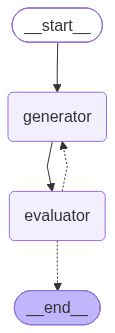

总迭代次数: 2
最终评级: pass
优化过程:
   [gen] LangGraph 的 Evaluator-Optimizer 模式是一种通过迭代反馈提升生成质量的工作流。它包含两个核...
   [eval] fail: 草稿整体结构清晰、语言流畅，约 160 字，基本符合篇幅要求，也覆盖了模式的核心机制。但存在几处不准确与可改进之处：

...
   [gen] LangGraph 的 Evaluator-Optimizer 是一种处理“输出质量不确定、需反复打磨”任务的经典编排模...
   [eval] pass: 草稿整体达标：字数约 200 字（150 字左右可接受），结构清晰，先给定位与两个核心节点，再讲循环机制与终止条件，最后...


LangGraph 的 Evaluator-Optimizer 是一种处理“输出质量不确定、需反复打磨”任务的经典编排模式，常与 Reflection 一并讨论。它包含生成器与评估器两个核心节点：生成器先产出初步结果，评估器依据显式定义的评判标准对其打分与批评；若未达标，则把评估反馈回传给生成器，由其据此修订结果，如此循环，直至通过或达到最大迭代次数。该模式适合有客观评判标准、单次生成难以稳定的任务，如翻译、代码生成与复杂问答，能显著提升输出的准确性与一致性。

In [1]:
import operator
from typing import Annotated, TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import SystemMessage, HumanMessage
from langchain.chat_models import init_chat_model
from pydantic import BaseModel, Field
from IPython.display import Image, display, Markdown

# ---------------- 1. LLM ----------------
llm = init_chat_model("deepseek-chat")

# ---------------- 2. 结构化输出模型 ----------------
class Feedback(BaseModel):
    """评估者返回的反馈结构"""
    grade: Literal["pass", "fail"] = Field(
        description="评估结论：pass 表示达标可结束，fail 表示需要继续优化"
    )
    feedback: str = Field(
        description="具体的改进建议，指出内容存在的问题与优化方向"
    )

# 评估者：绑定结构化输出，强制返回 Feedback
evaluator = llm.with_structured_output(Feedback)

# ---------------- 3. State 定义 ----------------
class State(TypedDict):
    task: str                                       # 原始任务（不变）
    draft: str                                      # 当前草稿（每轮更新）
    feedback: str                                   # 当前反馈
    grade: Literal["pass", "fail"]                  # 当前评级
    iterations: Annotated[int, operator.add]        # 迭代次数累加
    max_iterations: int                             # 上限，防止死循环
    history: Annotated[list, operator.add]          # 历史记录（可选）

# ---------------- 4. 节点：生成者 ----------------
def generator(state: State):
    """生成者：根据任务（+可选反馈）生成或优化草稿"""
    if state.get("feedback"):
        # 有反馈 → 按反馈优化已有草稿
        messages = [
            SystemMessage(content=(
                "You are a writer. Improve the existing draft based on the "
                "reviewer's feedback. Keep the good parts, fix the issues. "
                "Output only the improved content, no preamble."
            )),
            HumanMessage(content=(
                f"Task: {state['task']}\n\n"
                f"Current draft:\n{state['draft']}\n\n"
                f"Reviewer feedback:\n{state['feedback']}"
            )),
        ]
    else:
        # 没反馈 → 首次生成
        messages = [
            SystemMessage(content=(
                "You are a writer. Write a first draft for the given task. "
                "Output only the content, no preamble."
            )),
            HumanMessage(content=f"Task: {state['task']}"),
        ]

    result = llm.invoke(messages)
    return {
        "draft": result.content,
        "iterations": 1,                # 每轮 +1
        "history": [f"[gen] {result.content[:60]}..."],
    }

# ---------------- 5. 节点：评估者 ----------------
def evaluate(state: State):
    """评估者：对当前草稿给出 pass/fail 和反馈"""
    result = evaluator.invoke([
        SystemMessage(content=(
            "You are a strict reviewer. Evaluate the draft against the task. "
            "Give 'pass' only if it's genuinely good; otherwise 'fail' with "
            "concrete, actionable feedback."
        )),
        HumanMessage(content=(
            f"Task: {state['task']}\n\n"
            f"Draft:\n{state['draft']}"
        )),
    ])
    return {
        "grade": result.grade,
        "feedback": result.feedback,
        "history": [f"[eval] {result.grade}: {result.feedback[:60]}..."],
    }

# ---------------- 6. 条件边：是否继续循环 ----------------
def should_continue(state: State) -> Literal["generator", "__end__"]:
    """评估者后判断：达标 / 超上限 → 结束；否则回到生成者"""
    if state["grade"] == "pass":
        return END
    if state["iterations"] >= state["max_iterations"]:
        return END
    return "generator"

# ---------------- 7. 构建图 ----------------
builder = StateGraph(State)
builder.add_node("generator", generator)
builder.add_node("evaluator", evaluate)

builder.add_edge(START, "generator")
builder.add_edge("generator", "evaluator")
builder.add_conditional_edges(
    "evaluator",
    should_continue,
    {"generator": "generator", END: END},
)

graph = builder.compile()

# ---------------- 8. 展示 & 运行 ----------------
display(Image(graph.get_graph().draw_mermaid_png()))

result = graph.invoke({
    "task": "写一段 150 字左右的简介，介绍 LangGraph 的 Evaluator-Optimizer 模式",
    "draft": "",
    "feedback": "",
    "grade": "fail",
    "iterations": 0,
    "max_iterations": 3,
    "history": [],
})

print("总迭代次数:", result["iterations"])
print("最终评级:", result["grade"])
print("优化过程:")
for h in result["history"]:
    print("  ", h)

Markdown(result["draft"])